In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
import pandas as pd
import urllib.request
import zipfile
import io
url="https://archive.ics.uci.edu/static/public/360/air+quality.zip"
req=urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    zip_file = zipfile.ZipFile(io.BytesIO(response.read()))
    excel_file_name = [name for name in zip_file.namelist() if name.endswith('.xlsx')][0]
    with zip_file.open(excel_file_name) as f:
        df=pd.read_excel(f)
print(df.head())
print(df.shape)
print(df.info())

        Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)   C6H6(GT)  \
0 2004-03-10  18:00:00     2.6      1360.00       150  11.881723   
1 2004-03-10  19:00:00     2.0      1292.25       112   9.397165   
2 2004-03-10  20:00:00     2.2      1402.00        88   8.997817   
3 2004-03-10  21:00:00     2.2      1375.50        80   9.228796   
4 2004-03-10  22:00:00     1.6      1272.25        51   6.518224   

   PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)  \
0        1045.50    166.0       1056.25    113.0       1692.00      1267.50   
1         954.75    103.0       1173.75     92.0       1558.75       972.25   
2         939.25    131.0       1140.00    114.0       1554.50      1074.00   
3         948.25    172.0       1092.00    122.0       1583.75      1203.25   
4         835.50    131.0       1205.00    116.0       1490.00      1110.00   

       T         RH        AH  
0  13.60  48.875001  0.757754  
1  13.30  47.700000  0.725487  
2  11.90  53.975000 

In [ ]:
df=df.dropna(axis=1,how="all")
df=df.replace(-200,np.nan)
df=df.dropna(subset=["CO(GT)"])
print(df.isnull().sum())

Date                0
Time                0
CO(GT)              0
PT08.S1(CO)       330
NMHC(GT)         6784
C6H6(GT)          330
PT08.S2(NMHC)     330
NOx(GT)           413
PT08.S3(NOx)      330
NO2(GT)           416
PT08.S4(NO2)      330
PT08.S5(O3)       330
T                 330
RH                330
AH                330
dtype: int64


In [ ]:
df["Hour"] = pd.to_datetime(
    df["Time"].astype(str).str.replace(".", ":", regex=False),
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

df["Month"] = pd.to_datetime(
    df["Date"],
    format="%Y-%m-%d",
    errors="coerce"
).dt.month

print(df.head())

        Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)   C6H6(GT)  \
0 2004-03-10  18:00:00     2.6      1360.00     150.0  11.881723   
1 2004-03-10  19:00:00     2.0      1292.25     112.0   9.397165   
2 2004-03-10  20:00:00     2.2      1402.00      88.0   8.997817   
3 2004-03-10  21:00:00     2.2      1375.50      80.0   9.228796   
4 2004-03-10  22:00:00     1.6      1272.25      51.0   6.518224   

   PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)  \
0        1045.50    166.0       1056.25    113.0       1692.00      1267.50   
1         954.75    103.0       1173.75     92.0       1558.75       972.25   
2         939.25    131.0       1140.00    114.0       1554.50      1074.00   
3         948.25    172.0       1092.00    122.0       1583.75      1203.25   
4         835.50    131.0       1205.00    116.0       1490.00      1110.00   

       T         RH        AH  Hour  Month  
0  13.60  48.875001  0.757754    18      3  
1  13.30  47.700000  0.725

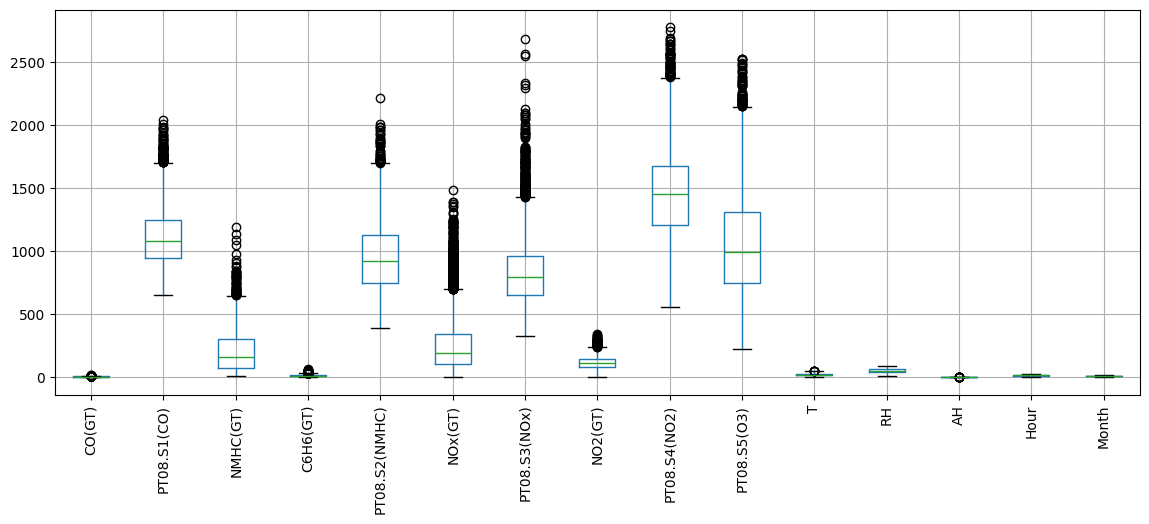

In [ ]:
df.select_dtypes(include=np.number).boxplot(figsize=(14,5))
plt.xticks(rotation=90)
plt.show()

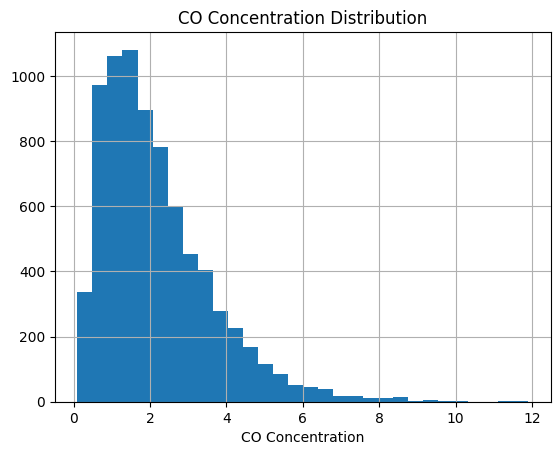

In [ ]:
df["CO(GT)"].hist(bins=30)
plt.title("CO Concentration Distribution")
plt.xlabel("CO Concentration")
plt.show()

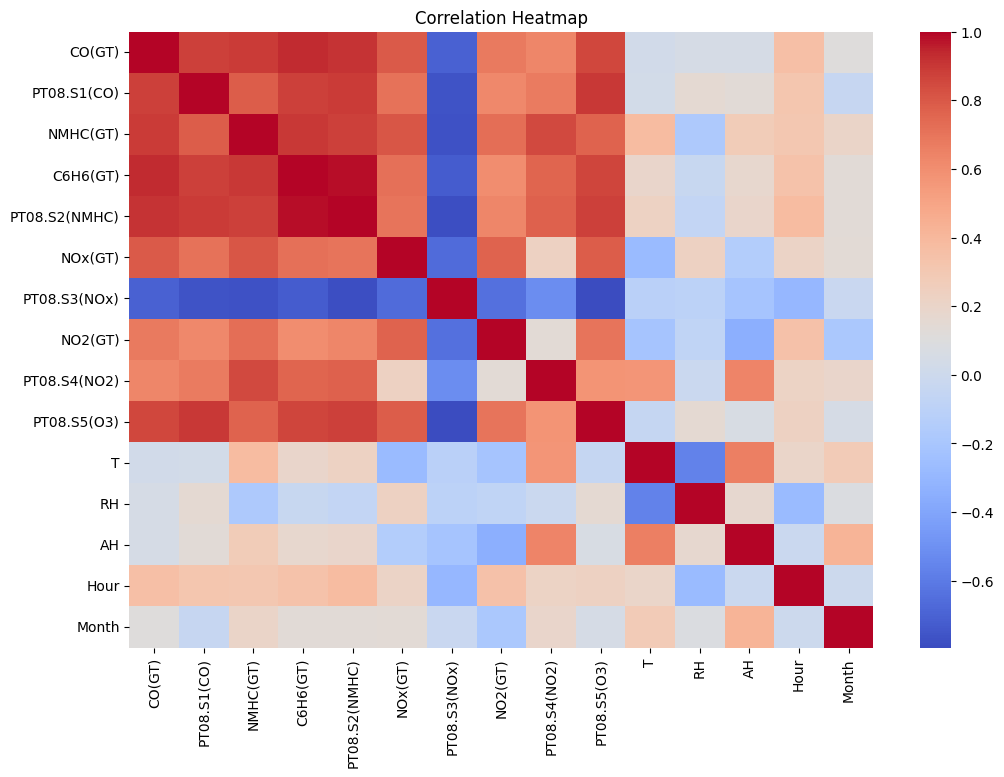

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes(include=np.number).corr(),cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
features = [
    "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)",
    "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)",
    "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)",
    "T", "RH", "AH", "Hour", "Month"]
data=df[features + ["CO(GT)"]].dropna(subset=["CO(GT)"])
data=data.sort_values(["Month","Hour"])
X=data[features]
y=data["CO(GT)"]
split=int(len(data)*0.70)
X_train,X_test=X.iloc[:split],X.iloc[split:]
y_train,y_test=y.iloc[:split],y.iloc[split:]
print(X_train.shape, X_test.shape)

(5371, 14) (2303, 14)


In [ ]:
def evaluate(model, name):
    pred=model.predict(X_test)
    print(name)
    print("MAE:",mean_absolute_error(y_test, pred))
    print("RMSE:",np.sqrt(mean_squared_error(y_test,pred)))
    print("R2:",r2_score(y_test,pred))

In [ ]:
from sklearn.linear_model import LinearRegression
lr=Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LinearRegression())])
lr.fit(X_train,y_train)
evaluate(lr,"Linear Regression")

Linear Regression
MAE: 0.36393532482221935
RMSE: 0.5959878582477821
R2: 0.8810649996871481


In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(random_state=42))])
dt.fit(X_train, y_train)
evaluate(dt, "Decision Tree")

Decision Tree
MAE: 0.5036039947894051
RMSE: 0.7540540309194095
R2: 0.8096119062813026


In [ ]:
from sklearn.neighbors import KNeighborsRegressor
knn=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scale",StandardScaler()),
    ("model",KNeighborsRegressor(n_neighbors=5))])
knn.fit(X_train,y_train)
evaluate(knn,"KNN")

KNN
MAE: 0.4770733825445072
RMSE: 0.7275441831450081
R2: 0.8227633228281044


In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("model",RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
rf.fit(X_train,y_train)
evaluate(rf,"Random Forest")

Random Forest
MAE: 0.3708952380952381
RMSE: 0.5982641040200583
R2: 0.880154772151411


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
gb=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("model",GradientBoostingRegressor(random_state=42))])
gb.fit(X_train,y_train)
evaluate(gb,"Gradient Boosting")

Gradient Boosting
MAE: 0.3519505192046806
RMSE: 0.5677101212562328
R2: 0.8920834314089052


In [ ]:
models = {
    "Linear Regression": lr,
    "Decision Tree": dt,
    "KNN": knn,
    "Random Forest": rf,
    "Gradient Boosting": gb }
results = []
for name, model in models.items():
    p = model.predict(X_test)
    results.append([
        name,
        mean_absolute_error(y_test, p),
        np.sqrt(mean_squared_error(y_test, p)),
        r2_score(y_test, p)])
comparison = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2"])
print(comparison)

               Model       MAE      RMSE        R2
0  Linear Regression  0.363935  0.595988  0.881065
1      Decision Tree  0.503604  0.754054  0.809612
2                KNN  0.477073  0.727544  0.822763
3      Random Forest  0.370895  0.598264  0.880155
4  Gradient Boosting  0.351951  0.567710  0.892083


In [ ]:
grid = GridSearchCV(
    rf,
    {
        "model__n_estimators":[100, 200],
        "model__max_depth":[10, 20, None]
    },
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1)
grid.fit(X_train,y_train)
best_model = grid.best_estimator_
print(grid.best_params_)
evaluate(best_model, "Tuned Random Forest")

{'model__max_depth': 20, 'model__n_estimators': 200}
Tuned Random Forest
MAE: 0.3715516903474933
RMSE: 0.6014119112335626
R2: 0.8788903067336434


In [ ]:
from sklearn.model_selection import cross_val_score
scores=cross_val_score(
    best_model, X_train, y_train,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error")
print("CV MAE:",-scores)
print("Average:",-scores.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['NMHC(GT)']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['NMHC(GT)']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


CV MAE: [0.44575243 0.30670405 0.30201365 0.21236965 0.19584581]
Average: 0.2925371177245182


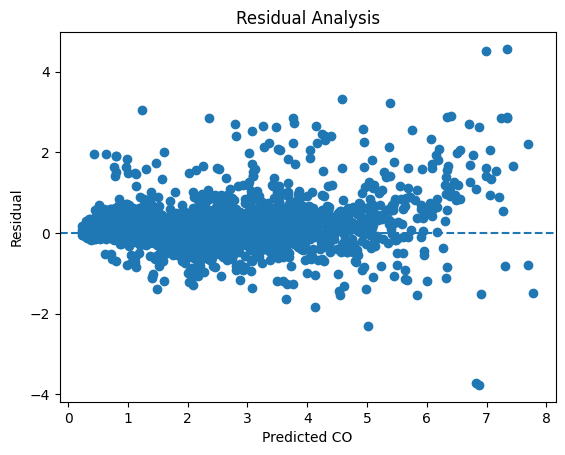

In [ ]:
pred=best_model.predict(X_test)
residual=y_test-pred
plt.scatter(pred, residual)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted CO")
plt.ylabel("Residual")
plt.title("Residual Analysis")
plt.show()

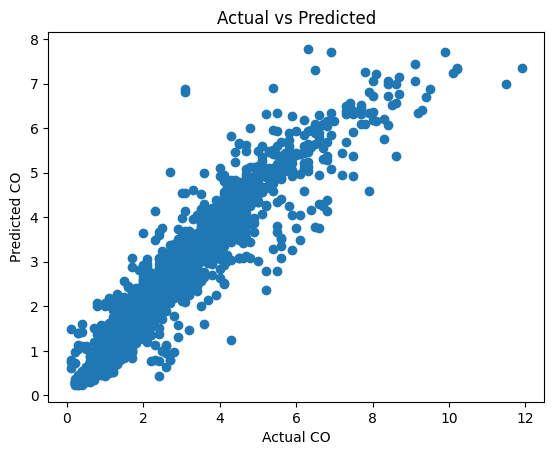

In [ ]:
plt.scatter(y_test, pred)
plt.xlabel("Actual CO")
plt.ylabel("Predicted CO")
plt.title("Actual vs Predicted")
plt.show()

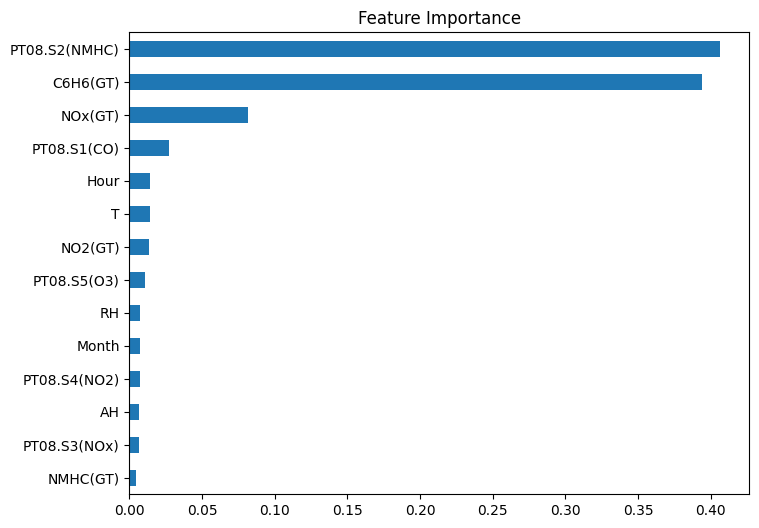

In [ ]:
importance=best_model.named_steps["model"].feature_importances_
pd.Series(importance, index=features).sort_values().plot(
    kind="barh", figsize=(8,6))
plt.title("Feature Importance")
plt.show()

In [ ]:
comparison.to_csv("Model_Comparison.csv",index=False)
print("Results saved successfully!")

Results saved successfully!


In [ ]:
models = {
    "Linear Regression": lr,
    "Decision Tree": dt,
    "K-Nearest Neighbours": knn,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "Tuned Random Forest": best_model
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred)
    })

final_results = pd.DataFrame(results)
display(final_results.round(4))

,Model,MAE,RMSE,R²
0,Linear Regression,0.3639,0.5960,0.8811
1,Decision Tree,0.5036,0.7541,0.8096
2,K-Nearest Neighbours,0.4771,0.7275,0.8228
3,Random Forest,0.3709,0.5983,0.8802
4,Gradient Boosting,0.3520,0.5677,0.8921
5,Tuned Random Forest,0.3716,0.6014,0.8789
